# 05 · Normalization and regularization, by experiment

**Lecture:** *Normalization and Regularization in Neural Networks* (04-09-2026) · **Notes:** `../notes/05_normalization_and_regularization.md`

Two different problems, two different toolboxes:

| | Normalization | Regularization |
|---|---|---|
| Problem it solves | badly **scaled** numbers make optimisation slow or unstable | the model **memorises** the training set (overfitting) |
| Goal | stable, fast training | better results on **unseen** data |
| Tools | standardisation, min-max, BatchNorm, LayerNorm | L1, L2, dropout, early stopping, augmentation, weight decay |

In this notebook you will:
1. **See** gradient descent fail on unscaled features and fly on standardised ones.
2. Compare min-max and standardisation with an outlier, and see why test statistics must never leak in.
3. Compute **BatchNorm** and **LayerNorm** by hand and check them against PyTorch.
4. Make a network **overfit**, then try every regulariser from the lecture on it, measured honestly.

Runs in about 2–3 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
rng = np.random.default_rng(0); torch.manual_seed(0)

## 1 · Why scale matters: gradient descent on raw vs standardised features

Predict a price from two features with very different scales: **x1 = a rating from 0 to 1**, and **x2 = a floor area from 500 to 3000**. The true rule is y = 3·x1 + 0.002·x2 (+ noise). We fit it with plain gradient descent.

raw          lr 1e-06: DIVERGED
raw          lr 1e-07: final loss 1.229
raw          lr 1e-08: final loss 1.230
standardised lr 0.01: final loss 0.0098, reached < 0.02 after 199 steps


standardised lr 0.1: final loss 0.0098, reached < 0.02 after 19 steps
standardised lr 0.5: final loss 0.0098, reached < 0.02 after 1 steps


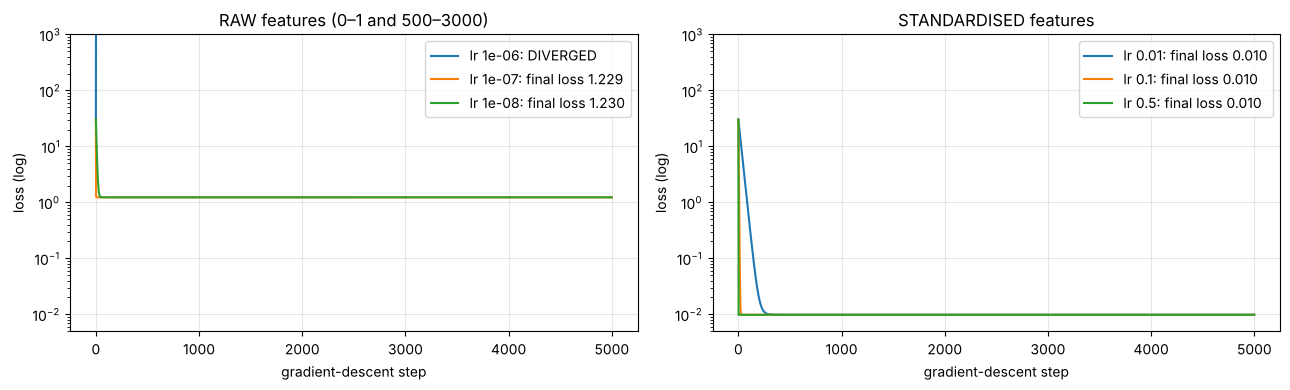

In [2]:
n = 200
x1 = rng.uniform(0, 1, n); x2 = rng.uniform(500, 3000, n)
y = 3 * x1 + 0.002 * x2 + rng.normal(0, 0.1, n)
X_raw = np.column_stack([x1, x2])

def gradient_descent(X, y, lr, steps=5000):
    w, b, losses = np.zeros(X.shape[1]), 0.0, []
    for _ in range(steps):
        err = X @ w + b - y
        loss = (err ** 2).mean()
        if not np.isfinite(loss) or loss > 1e6:
            losses.append(np.inf); break
        losses.append(loss)
        w -= lr * 2 * X.T @ err / len(y); b -= lr * 2 * err.mean()
    return np.array(losses)

mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X_std = (X_raw - mu) / sigma                       # standardisation: (x - mean) / std

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in [1e-6, 1e-7, 1e-8]:
    L = gradient_descent(X_raw, y, lr)
    label = f"lr {lr:g}: " + ("DIVERGED" if np.isinf(L[-1]) else f"final loss {L[-1]:.3f}")
    axes[0].semilogy(L[np.isfinite(L)], label=label); print("raw         ", label)
for lr in [0.01, 0.1, 0.5]:
    L = gradient_descent(X_std, y, lr)
    first = int(np.argmax(L < 0.02)) if (L < 0.02).any() else None
    axes[1].semilogy(L, label=f"lr {lr:g}: final loss {L[-1]:.3f}"); print("standardised", f"lr {lr:g}: final loss {L[-1]:.4f}, reached < 0.02 after {first} steps")
axes[0].set_title("RAW features (0–1 and 500–3000)"); axes[1].set_title("STANDARDISED features")
for ax in axes:
    ax.set_xlabel("gradient-descent step"); ax.set_ylabel("loss (log)"); ax.set_ylim(5e-3, 1e3); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What happened:**
- **Raw features:** the big feature x2 (hundreds to thousands) produces huge gradients, so the learning rate must be tiny to avoid **diverging**. But at that tiny rate the small feature x1 barely learns, and the loss **stalls**: the model is stuck far from the answer after 5,000 steps.
- **Standardised features:** both features are on the same scale, learning rates up to 100,000× larger are safe, and the loss reaches the noise floor in 199 steps (lr 0.01), 19 steps (lr 0.1) or even a single step (lr 0.5).

This is the lecture's point: normalization doesn't change **what** the model can learn, it makes the optimisation problem **easy to navigate**.

## 2 · Standardisation vs min-max, and data leakage

- **Standardisation (z-score):** x′ = (x − μ) / σ → mean 0, standard deviation 1.
- **Min-max scaling:** x′ = (x − min) / (max − min) → range [0, 1].
- **Images:** pixel / 255 → [0, 1].

### Outliers: min-max's weakness

In [3]:
salaries = np.r_[rng.normal(50, 10, 99), 1000]           # 99 normal salaries (in thousands) + one billionaire-style outlier
minmax = (salaries - salaries.min()) / (salaries.max() - salaries.min())
zscore = (salaries - salaries.mean()) / salaries.std()
print(f"min-max: the 99 normal values all lie in [{minmax[:99].min():.3f}, {minmax[:99].max():.3f}]  (squashed into {100 * (minmax[:99].max() - minmax[:99].min()):.0f}% of the range)")
print(f"z-score: the 99 normal values lie in [{zscore[:99].min():.2f}, {zscore[:99].max():.2f}], the outlier at {zscore[-1]:.1f}")

min-max: the 99 normal values all lie in [0.000, 0.049]  (squashed into 5% of the range)
z-score: the 99 normal values lie in [-0.35, 0.15], the outlier at 9.9


With min-max, one extreme value sets the range, so all the normal values get squashed into a tiny sliver near 0. Standardisation is affected too (the outlier shifts the mean and inflates σ), but less dramatically. For heavy outliers, people use robust scaling (median and interquartile range) or clip the outliers first.

### Data leakage: fit the scaler on the training set ONLY

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
X_tr, X_te = train_test_split(X_raw, test_size=0.3, random_state=0)
right = StandardScaler().fit(X_tr)                 # learns mu and sigma from TRAIN data only
wrong = StandardScaler().fit(np.vstack([X_tr, X_te]))  # peeks at the test set
print("mean learned from train only:", right.mean_.round(3), "  from train+test:", wrong.mean_.round(3))
X_tr_s, X_te_s = right.transform(X_tr), right.transform(X_te)   # SAME train statistics applied to both
print("test set after correct scaling: mean", X_te_s.mean(axis=0).round(3), "(not exactly 0, and that's fine)")

mean learned from train only: [5.360000e-01 1.763709e+03]   from train+test: [5.400000e-01 1.804361e+03]
test set after correct scaling: mean [0.045 0.192] (not exactly 0, and that's fine)


The rule from the lecture: **compute μ and σ (or min/max) from the training data, then apply those same numbers to validation and test data.** If test data helps choose the scaling, information about the test set has leaked into training, and the reported test score is no longer a fair "unseen data" score. Here the difference in μ is small, but in real projects (time series, small data, data from different hospitals) leakage can make results look much better than they really are.

## 3 · Normalization inside the network: BatchNorm and LayerNorm

### BatchNorm by hand
For each **feature**, using the statistics of the **mini-batch**:

μ_B = mean over the batch · σ²_B = variance over the batch · x̂ = (x − μ_B) / √(σ²_B + ε) · y = γ·x̂ + β (γ, β learned)

In [5]:
torch.manual_seed(0)
batch = torch.randn(8, 4) * torch.tensor([1., 10., 0.1, 5.]) + torch.tensor([0., 50., -3., 7.])   # 8 samples, 4 features on wild scales
bn = nn.BatchNorm1d(4)                     # gamma starts at 1, beta at 0
bn.train()
out_torch = bn(batch)

mu_B = batch.mean(dim=0)                   # per FEATURE, across the batch
var_B = batch.var(dim=0, unbiased=False)
out_hand = (batch - mu_B) / torch.sqrt(var_B + bn.eps) * bn.weight + bn.bias
print("matches PyTorch:", torch.allclose(out_hand, out_torch, atol=1e-5))
print("per-feature mean after BN:", out_torch.mean(0).detach().numpy().round(3), " std:", out_torch.std(0, unbiased=False).detach().numpy().round(3))
print("running mean kept for inference:", bn.running_mean.numpy().round(2), "(moved 10% of the way towards this batch's mean, momentum 0.1)")

matches PyTorch: True
per-feature mean after BN: [-0.  0. -0.  0.]  std: [1.    1.    0.998 1.   ]
running mean kept for inference: [ 0.02  4.66 -0.3   0.67] (moved 10% of the way towards this batch's mean, momentum 0.1)


### Training mode vs inference mode
During training BatchNorm uses **the current batch's** statistics. At inference there may be just **one** example (no meaningful batch), so it uses the **running averages** it collected during training. That's why `model.eval()` matters:

In [6]:
single = batch[:1]
bn.train(); print("train mode, one sample:", bn(torch.cat([single, single])).detach()[0].numpy().round(3), " <- batch of identical rows: variance 0, so everything becomes 0")
bn.eval();  print("eval mode,  one sample:", bn(single).detach()[0].numpy().round(3), " <- uses running statistics")

train mode, one sample: [-0.  0.  0.  0.]  <- batch of identical rows: variance 0, so everything becomes 0
eval mode,  one sample: [-1.09   7.508 -2.727  1.898]  <- uses running statistics


### LayerNorm by hand
For each **sample**, using the statistics of **its own features**. It doesn't depend on the batch at all, which is why transformers and sequence models use it.

In [7]:
ln = nn.LayerNorm(4)
out_ln = ln(batch)
mu_L = batch.mean(dim=1, keepdim=True)              # per SAMPLE, across its features
var_L = batch.var(dim=1, unbiased=False, keepdim=True)
out_ln_hand = (batch - mu_L) / torch.sqrt(var_L + ln.eps) * ln.weight + ln.bias
print("matches PyTorch:", torch.allclose(out_ln_hand, out_ln, atol=1e-5))
print("each SAMPLE now has mean ~0:", out_ln.mean(1).detach().numpy().round(3))
print("same output for one sample alone as inside the batch:", torch.allclose(ln(batch[:1]), out_ln[:1], atol=1e-6))

matches PyTorch: True
each SAMPLE now has mean ~0: [ 0. -0. -0.  0.  0. -0.  0.  0.]
same output for one sample alone as inside the batch: True


| | BatchNorm | LayerNorm |
|---|---|---|
| averages over | the **batch** (per feature/channel) | the **features** (per sample) |
| depends on batch size | yes (very small batches give noisy statistics) | no |
| train vs eval behaviour | different (running statistics) | identical |
| typical home | CNNs, feed-forward nets | transformers, RNNs |

### Does BatchNorm actually help training? A 10-layer network on digits

no   BatchNorm: validation accuracy after 5 epochs 10.0%, after 30 epochs 10.0%


with BatchNorm: validation accuracy after 5 epochs 89.4%, after 30 epochs 97.5%


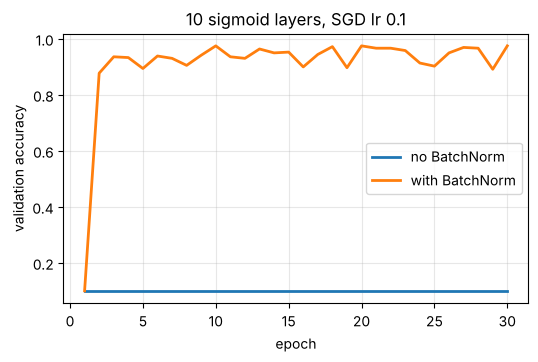

In [8]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd, yd = digits.data / 16.0, digits.target       # image normalisation: pixels 0..16 -> 0..1
Xtr_all, Xtmp, ytr_all, ytmp = train_test_split(Xd, yd, test_size=0.4, random_state=0, stratify=yd)
Xva_all, Xte_all, yva_all, yte_all = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=0, stratify=ytmp)
T = lambda a: torch.tensor(a, dtype=torch.float32)

def deep_net(use_bn, depth=10, width=64):
    layers, d_in = [], 64
    for _ in range(depth):
        layers += [nn.Linear(d_in, width)] + ([nn.BatchNorm1d(width)] if use_bn else []) + [nn.Sigmoid()]
        d_in = width
    return nn.Sequential(*layers, nn.Linear(d_in, 10))

curves = {}
for use_bn in [False, True]:
    torch.manual_seed(0); net = deep_net(use_bn)
    opt = torch.optim.SGD(net.parameters(), lr=0.1)
    Xt, yt = T(Xtr_all), torch.tensor(ytr_all)
    accs = []
    for epoch in range(30):
        net.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 32):
            idx = perm[i:i + 32]
            loss = nn.functional.cross_entropy(net(Xt[idx]), yt[idx]); opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            accs.append((net(T(Xva_all)).argmax(1) == torch.tensor(yva_all)).float().mean().item())
    curves["with BatchNorm" if use_bn else "no BatchNorm"] = accs
    print(f"{'with' if use_bn else 'no  '} BatchNorm: validation accuracy after 5 epochs {accs[4]:.1%}, after 30 epochs {accs[-1]:.1%}")
plt.figure(figsize=(6, 3.5))
for k, v in curves.items(): plt.plot(range(1, 31), v, label=k, lw=2)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.title("10 sigmoid layers, SGD lr 0.1"); plt.legend(); plt.grid(alpha=0.3); plt.show()

A deep sigmoid network is the textbook hard case (notebook 04 showed its gradients vanish). Without BatchNorm it **doesn't learn at all** in 30 epochs (10% = guessing among 10 digits). Inserting BatchNorm after every linear layer keeps each layer's inputs centred and scaled, so the sigmoids stay out of their flat regions, and the same network reaches about 89% after 5 epochs and 97.5% after 30.

## 4 · Regularization: make a network overfit, then fight it

To see overfitting clearly we make it easy to happen: only **200** training images, and a **big** network (64 → 512 → 512 → 10, about 300,000 weights). We keep a **validation** set to make decisions and a separate **test** set we look at only at the end.

train 200  validation 798  test 799


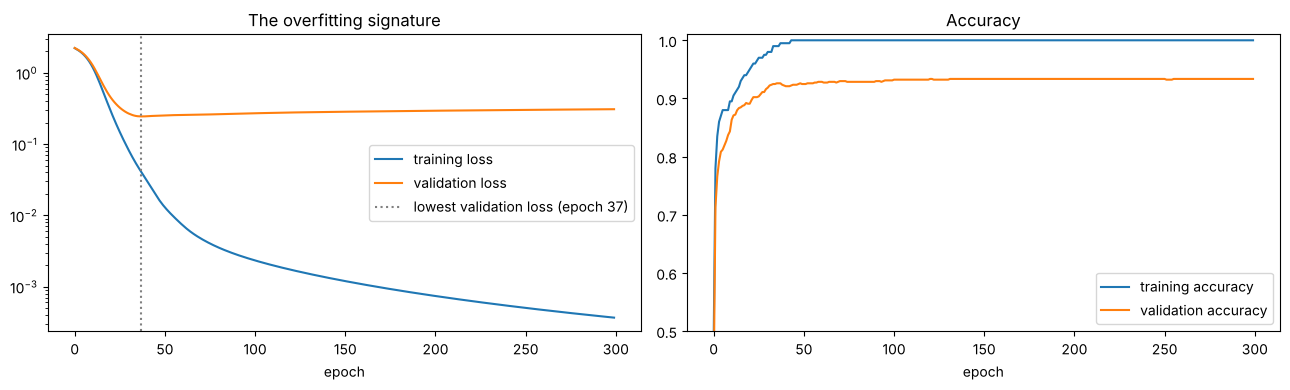

training accuracy 100.0%, validation accuracy 93.4%
validation loss: lowest 0.245 at epoch 37, at the end 0.309


In [9]:
Xtr, Xtmp, ytr, ytmp = train_test_split(Xd, yd, train_size=200, random_state=0, stratify=yd)
Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=0, stratify=ytmp)
Xtr, Xva, Xte = T(Xtr), T(Xva), T(Xte); ytr, yva, yte = torch.tensor(ytr), torch.tensor(yva), torch.tensor(yte)
print("train", len(Xtr), " validation", len(Xva), " test", len(Xte))

def big_net(p_drop=0.0):
    return nn.Sequential(nn.Linear(64, 512), nn.ReLU(), nn.Dropout(p_drop),
                         nn.Linear(512, 512), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(512, 10))

def evaluate(net, X, y):
    net.eval()
    with torch.no_grad():
        out = net(X); loss = nn.functional.cross_entropy(out, y).item(); acc = (out.argmax(1) == y).float().mean().item()
    net.train(); return loss, acc

def shift_1px(X):
    """data augmentation: move each 8x8 digit by up to 1 pixel (label unchanged)"""
    imgs = X.view(-1, 8, 8).clone()
    dx, dy = np.random.randint(-1, 2, size=(2, len(imgs)))
    for i in range(len(imgs)):
        imgs[i] = torch.roll(imgs[i], shifts=(int(dy[i]), int(dx[i])), dims=(0, 1))
    return imgs.view(-1, 64)

def train_reg(p_drop=0.0, l1=0.0, l2=0.0, weight_decay=0.0, optimizer="adam", augment=False, epochs=300, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    net = big_net(p_drop)
    Opt = torch.optim.AdamW if optimizer == "adamw" else torch.optim.Adam
    opt = Opt(net.parameters(), lr=1e-3, weight_decay=weight_decay)
    hist = []
    for epoch in range(epochs):
        xb = shift_1px(Xtr) if augment else Xtr
        loss = nn.functional.cross_entropy(net(xb), ytr)
        weights = [m.weight for m in net if isinstance(m, nn.Linear)]
        if l1: loss = loss + l1 * sum(w.abs().sum() for w in weights)          # L1 penalty: lambda * sum|w|
        if l2: loss = loss + l2 / 2 * sum((w ** 2).sum() for w in weights)     # L2 penalty: lambda/2 * sum w^2
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(net, Xtr, ytr) + evaluate(net, Xva, yva))         # (train loss, train acc, val loss, val acc)
    return net, np.array(hist)

net0, h0 = train_reg()
best_epoch = int(h0[:, 2].argmin())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(h0[:, 0], label="training loss"); axes[0].plot(h0[:, 2], label="validation loss")
axes[0].axvline(best_epoch, color="grey", ls=":", label=f"lowest validation loss (epoch {best_epoch})")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].set_title("The overfitting signature")
axes[1].plot(h0[:, 1], label="training accuracy"); axes[1].plot(h0[:, 3], label="validation accuracy")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].set_title("Accuracy"); axes[1].set_ylim(0.5, 1.01)
plt.tight_layout(); plt.show()
print(f"training accuracy {h0[-1, 1]:.1%}, validation accuracy {h0[-1, 3]:.1%}")
print(f"validation loss: lowest {h0[best_epoch, 2]:.3f} at epoch {best_epoch}, at the end {h0[-1, 2]:.3f}")

This is the **overfitting signature** from the lecture:
- **training loss keeps falling** towards 0, and training accuracy hits 100% (memorised);
- **validation loss bottoms out and then rises.** The network grows ever more confident on the training images in ways that don't carry over, so on unseen images its wrong answers become more confidently wrong.

Validation **accuracy** often plateaus rather than collapsing, which is why the lecture says to **compare losses, not just training accuracy**.

### Every regulariser from the lecture, on the same problem
Each setting is trained 3 times (3 random seeds) and averaged, because single runs on 200 images are noisy.

In [10]:
settings = {
    "no regularization":          dict(),
    "L2 penalty (lambda 1e-3)":   dict(l2=1e-3),
    "L1 penalty (lambda 1e-4)":   dict(l1=1e-4),
    "dropout p = 0.5":            dict(p_drop=0.5),
    "augmentation (1-px shift)":  dict(augment=True),
    "Adam + weight_decay 1e-2":   dict(weight_decay=1e-2),
    "AdamW weight_decay 1e-2":    dict(weight_decay=1e-2, optimizer="adamw"),
}
rows = []
for name, kw in settings.items():
    final_val, final_test, es_test, zeros = [], [], [], []
    for seed in range(3):
        net, h = train_reg(seed=seed, **kw)
        final_val.append(h[-1, 3]); final_test.append(evaluate(net, Xte, yte)[1])
        weights = torch.cat([m.weight.detach().flatten() for m in net if isinstance(m, nn.Linear)])
        zeros.append((weights.abs() < 1e-3).float().mean().item())
    rows.append((name, np.mean(final_val), np.mean(final_test), np.std(final_test), np.mean(zeros)))
print(f"{'setting':>27} {'val acc':>8} {'test acc':>14} {'weights ~0':>11}")
for name, va, te, sd, z in rows:
    print(f"{name:>27} {va:>8.1%} {te:>8.1%} ± {sd:.1%} {z:>10.0%}")

                    setting  val acc       test acc  weights ~0
          no regularization    93.4%    93.5% ± 0.3%         2%
   L2 penalty (lambda 1e-3)    93.9%    94.1% ± 0.2%        24%
   L1 penalty (lambda 1e-4)    93.7%    93.7% ± 0.2%        88%
            dropout p = 0.5    94.1%    93.9% ± 0.5%         2%
  augmentation (1-px shift)    93.1%    91.8% ± 0.6%         2%
   Adam + weight_decay 1e-2    93.6%    93.7% ± 0.2%        24%
    AdamW weight_decay 1e-2    93.5%    93.5% ± 0.3%         2%


### Early stopping
Keep training, but remember the weights from the epoch with the **lowest validation loss**, and stop once it hasn't improved for `patience` epochs.

In [11]:
import copy
def train_early_stopping(patience=20, max_epochs=300, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    net = big_net(); opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    best_loss, best_state, best_epoch, waited = np.inf, None, 0, 0
    for epoch in range(max_epochs):
        loss = nn.functional.cross_entropy(net(Xtr), ytr); opt.zero_grad(); loss.backward(); opt.step()
        val_loss, _ = evaluate(net, Xva, yva)
        if val_loss < best_loss:
            best_loss, best_state, best_epoch, waited = val_loss, copy.deepcopy(net.state_dict()), epoch, 0
        else:
            waited += 1
            if waited >= patience:
                break
    net.load_state_dict(best_state)
    return net, best_epoch, epoch

es_acc = []
for seed in range(3):
    net, best_ep, stopped = train_early_stopping(seed=seed)
    es_acc.append(evaluate(net, Xte, yte)[1])
    print(f"seed {seed}: best validation loss at epoch {best_ep}, stopped at epoch {stopped} (instead of 300), test accuracy {es_acc[-1]:.1%}")
print(f"early stopping: test accuracy {np.mean(es_acc):.1%} ± {np.std(es_acc):.1%}")

seed 0: best validation loss at epoch 37, stopped at epoch 57 (instead of 300), test accuracy 93.5%


seed 1: best validation loss at epoch 36, stopped at epoch 56 (instead of 300), test accuracy 92.7%


seed 2: best validation loss at epoch 50, stopped at epoch 70 (instead of 300), test accuracy 93.4%
early stopping: test accuracy 93.2% ± 0.3%


### Honest reading of the regularization results

Before reading the tables: with 200 training images and 3 seeds, differences of about **±1 percentage point are within the noise**. Look for patterns, not for a winner.

- **L1 does exactly what the lecture says to the weights.** It drives most weights to (almost) zero, making the network **sparse**. Compare the "weights ~0" column with the others. Its effect on accuracy is modest.
- **L2 (penalty in the loss) and Adam's `weight_decay`** behave alike (both leave about 24% of the weights near zero), because with Adam, `weight_decay` is just an L2 term added to the gradient.
- **AdamW** applies **decoupled** decay directly to the weights: each step shrinks w by lr × weight_decay × w = 0.001 × 0.01 = 0.001% here, which over 300 steps is very weak. That's why its row looks like no regularization. Same number, different mechanism: the lecture's reason AdamW exists. In practice AdamW is used with larger values (e.g. 0.05–0.1) and longer training.
- **The best test results came from L2 (94.1%) and dropout (93.9%)**, both about half a point above no regularization (93.5%). That gain is real but small, about the size of the seed-to-seed noise.
- **Early stopping** gave a similar test accuracy (93.2% vs 93.5%), but stopped after about 60 epochs instead of 300 (5× cheaper) and kept the weights from the lowest validation loss.
- **Augmentation by 1-pixel shifts did not help here.** On an 8×8 digit a 1-pixel shift is a big change (12% of the width) and `torch.roll` wraps pixels around the edge. The lecture's warning applies: *"incorrect transformations can create mislabeled or unrealistic examples"*. On real-sized images, small shifts and crops are standard and usually help.
- **None of them is magic.** The model still reaches 100% training accuracy, and the gap to validation shrinks a little. The biggest single cure for overfitting is **more data**.

> **Rule from the lecture:** establish a clear **baseline** first, then add regularization one change at a time, judging on **validation** data. Look at the test set only once, at the end.

## ✅ Check yourself
1. Normalization or regularization: which one is mainly about optimisation, and which about generalisation? *(normalization: optimisation; regularization: generalisation)*
2. Why did gradient descent on raw features either diverge or stall? *(x2's large scale forces a tiny learning rate, at which x1 barely learns)*
3. A feature has one huge outlier. Min-max or standardisation, and why? *(standardisation, or robust scaling; min-max squashes everything else into a tiny range)*
4. You compute μ and σ on the whole dataset before splitting. What's wrong? *(data leakage: the test set influenced training, so the score is optimistic)*
5. BatchNorm vs LayerNorm: what does each average over? Which one behaves differently in train and eval mode? *(batch per feature vs features per sample; BatchNorm)*
6. What does L1 do to weights that L2 doesn't? *(drives many exactly or nearly to zero: sparsity)*
7. How do you spot overfitting from the curves? *(training loss keeps falling while validation loss stops improving or rises)*
8. Why does AdamW exist? *(with Adam, adding L2 to the loss is not the same as true weight decay; AdamW decouples the decay from the adaptive gradient step)*